# Week 3: eQTL Discovery, Linking Genotype to Gene Expression

## This week at a glance

**Big idea:** This week I connect my two datasets. For one gene, I test every nearby SNP to see if people with more copies of an allele express the gene more (or less). A SNP that does this is an **eQTL**. eQTLs are the bridge between a SNP and a trait: many disease SNPs probably work by turning a gene's "volume knob" up or down.

**What I cover**
- What an eQTL is, and cis vs. trans
- How a linear regression slope and p-value test one SNP
- Why testing hundreds of SNPs needs a stricter cutoff (Bonferroni)
- How to read a LocusZoom plot, and why LD makes a "tower" of significant SNPs

**My readings**
| Paper | What I read | Why it matters |
|---|---|---|
| GTEx Consortium 2020, *Science* | Whole paper | The landmark cis-eQTL study across 49 human tissues, and the model for this project |
| Nathan et al. 2022, *Nature* | Methods only (compare models to GTEx) | eQTLs in single cells, and why the model has to change |
| AJHG 2020 paper on the course site | Skim the structure | How a scientific paper is laid out (abstract, introduction, methods, results, discussion) |

**My tasks**
1. Match people's sample IDs between the 1000 Genomes genotype data and the gene expression data.
2. Pick one gene and run an eQTL analysis using only SNPs within ±500 kb of the gene.
3. Pick a software tool (I use simple linear regression in Python).
4. Bonus: make a LocusZoom-style plot of -log10(p-value) vs. SNP position.

**Weekly questions I answer on Gradescope**
1. What does pleiotropy mean?
2. Do eQTLs tend to be shared across cell types?
3. How many SNPs tend to be in a 1 Mb window around a gene?

**My data**
- Genotypes: 1000 Genomes European samples (`../data/raw/LDREF/`)
- Gene expression: Geuvadis blood cell RNA-seq (`../data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt`)
- My gene: **ERAP2** on chromosome 5

## Biology background and vocabulary

### What is an eQTL?

An **eQTL** (expression quantitative trait locus) is a SNP where the number of copies of an allele is linked to how much a gene is expressed.

Back to the cookbook: the SNP is a typo in the **volume knob** next to a recipe. People with the typo make more (or fewer) photocopies of that recipe.

```
                  copies of allele T    ERAP2 expression
Person 1:   C C          0                   low
Person 2:   C T          1                   medium
Person 3:   T T          2                   high
```

If expression goes up (or down) step by step with the copies, that SNP is an eQTL for the gene. The gene it affects is called an **eGene**.

### cis vs. trans

| | cis-eQTL | trans-eQTL |
|---|---|---|
| Where the SNP is | Near the gene (usually within 1 Mb) | Far away, often on another chromosome |
| How common | Very common: GTEx found one for almost every gene | Rare and harder to find |
| This week | **Yes** | No |

I only test SNPs within **500 kb (500,000 letters) on each side** of the gene. This is the **cis window**, 1 Mb wide in total. Testing only nearby SNPs means far fewer tests, and nearby SNPs are where most regulatory knobs are.

### Testing one SNP: linear regression

For each SNP, I plot every person as a dot:
- **x** = copies of the counted allele (0, 1, 2)
- **y** = how much that person expresses the gene

Then I fit the best straight line through the dots.

**Toy example (6 people):**

| Person | Copies (x) | Expression (y) |
|---|---|---|
| A | 0 | 10 |
| B | 0 | 12 |
| C | 1 | 19 |
| D | 1 | 21 |
| E | 2 | 30 |
| F | 2 | 28 |

- Average at 0 copies = 11, at 1 copy = 20, at 2 copies = 29
- Each extra copy adds about 9, so the **slope (effect size) is about 9**
- The dots sit very close to the line, so this pattern would be very unlikely by luck: the **p-value is tiny**

| Result | What it means |
|---|---|
| **Slope (beta)** | How much expression changes per extra copy. Positive = more copies, more expression. Negative = more copies, less expression |
| **p-value** | If the SNP truly did nothing, how likely is a pattern this strong just by luck? Small = probably real |
| **R²** | Share of the differences in expression between people that the SNP explains (0 to 1) |

### Testing many SNPs: the Bonferroni cutoff

The usual cutoff is p < 0.05, which means a 5% chance of a false alarm **per test**. ERAP2's window has 510 SNPs. If none did anything, about 510 x 0.05 = **25 SNPs would still pass by luck**.

**Bonferroni** fixes this by dividing the cutoff by the number of tests:

**Bonferroni cutoff = 0.05 / number of SNPs tested**

For 510 SNPs: 0.05 / 510 = **0.000098**. Only SNPs below that count as significant.

### -log10(p): turning tiny p-values into heights

P-values like 0.000000001 are hard to compare, so I plot **-log10(p)**, which is about "how many zeros after the decimal point".

| p-value | -log10(p) |
|---|---|
| 0.1 | 1 |
| 0.01 | 2 |
| 0.000001 | 6 |
| 1e-100 | 100 |

Taller = more significant.

### LocusZoom plot

- **x-axis:** where each SNP is on the chromosome
- **y-axis:** -log10(p) for that SNP
- A dashed line marks the Bonferroni cutoff

A real eQTL usually looks like a **tower**, not one dot. That's because of **LD** (linkage disequilibrium): SNPs close together are inherited together, so if one SNP turns the knob, its neighbors look like they do too. This means the tallest dot isn't necessarily the SNP that causes the effect. Narrowing down the true one is called **fine-mapping**.

### Pleiotropy

**Pleiotropy** is when one genetic variant affects more than one trait. For eQTLs, this can mean one SNP changes the expression of two different genes, or a SNP that changes a gene's expression also changes disease risk. GTEx found a median of 57% of eQTL SNPs were linked to more than one gene in the same tissue.

### Tissues and cell types

The same SNP can turn a knob in one tissue (like blood) but not another (like brain), because each tissue uses different genes and different knobs. GTEx found eQTLs tend to be **either shared by almost all tissues or specific to just a few**, and tissues made of similar cell types share more eQTLs. My expression data comes from one cell type: lab-grown blood cells (LCLs).

### Week 3 terms

| Term | Meaning |
|---|---|
| **eQTL** | A SNP linked to how much a gene is expressed |
| **eGene** | A gene with at least one significant eQTL |
| **cis / trans** | SNP near the gene / far from the gene |
| **cis window** | The stretch of DNA around a gene where I test SNPs (±500 kb) |
| **Effect size (beta, slope)** | Change in expression per extra copy of the counted allele |
| **p-value** | How likely a pattern this strong would show up by luck alone |
| **Multiple testing** | Running many tests raises the chance of false alarms |
| **Bonferroni** | Stricter cutoff: 0.05 / number of tests |
| **LocusZoom plot** | -log10(p) vs. position for SNPs around a gene |
| **Lead SNP** | The SNP with the smallest p-value |
| **Fine-mapping** | Figuring out which SNP in an LD tower actually causes the effect |
| **Pleiotropy** | One variant affecting more than one trait |

## Task: cis-eQTL analysis for ERAP2

**Why ERAP2:** ERAP2 helps immune cells show pieces of proteins to other immune cells. It's known to have a very strong eQTL, so it's a good gene for checking that my method works. It even shows up as an eGene in the Nathan et al. reading.

### Step 1: Find ERAP2 in the expression file

In [1]:
import numpy as np
import pandas as pd

expression_path = "../data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt"
expression_table = pd.read_csv(expression_path, sep="\t")

# ERAP2's gene ID (the version number after the dot can change, so I match on the start)
erap2_gene_id = "ENSG00000164308"
erap2_row = expression_table[expression_table["TargetID"].str.startswith(erap2_gene_id)]

erap2_chromosome = int(erap2_row["Chr"].iloc[0])
erap2_position = int(erap2_row["Coord"].iloc[0])

print("ERAP2 is on chromosome", erap2_chromosome, "at position", erap2_position)
erap2_row.iloc[:, :8]

ERAP2 is on chromosome 5 at position 96211643


,TargetID,Gene_Symbol,Chr,Coord,HG00096,HG00097,HG00099,HG00100
19074,ENSG00000164308.12,ENSG00000164308.12,5,96211643,4.968098,5.638067,33.014261,22.562585


**What I see:** I see ERAP2 is on chromosome 5, at position 96,211,643. Its expression already looks very different between people: the first two people are around 5, while the next two are about 33 and 23. That's the kind of variation an eQTL could explain.

### Step 2: Match the people in both datasets (Task 1)

The genotype files and the expression file list people in different orders. I keep only the people in both, in the genotype file's order, so person number 1 in the genotypes is person number 1 in the expression values.

In [ ]:
genotype_folder = "../data/raw/LDREF"

fam_column_names = ["family_id", "person_id", "dad_id", "mom_id", "sex", "trait_value"]
people_table = pd.read_csv(
    f"{genotype_folder}/1000G.EUR.{erap2_chromosome}.fam",
    sep=r"\s+", header=None, names=fam_column_names,
)

expression_people = set(expression_table.columns[4:])
is_in_both = people_table["person_id"].isin(expression_people).to_numpy()
shared_people = people_table.loc[is_in_both, "person_id"].tolist()

erap2_expression = erap2_row[shared_people].iloc[0].to_numpy(dtype=float)

print("People in both datasets:", len(shared_people))
print("First 5:", shared_people[:5])
print("Their ERAP2 expression:", erap2_expression[:5].round(2))

People in both datasets: 344
First 5: ['HG00096', 'HG00097', 'HG00099', 'HG00101', 'HG00102']
Their ERAP2 expression: [ 4.97  5.64 33.01 18.15  2.53]


**What I see:** I see the same 344 people I found in Week 2. Now their ERAP2 expression values are lined up in the same order as the genotype file, which is what lets me connect each person's genotype to their expression.

### Step 3: Pick the SNPs in the cis window

I keep SNPs within 500,000 letters on each side of ERAP2's position.

The same step in PLINK uses a 6-column coordinate file (chromosome, start, end, name, and two placeholder columns) with `--extract bed1`:

```bash
# erap2_window.txt:   5   95711643   96711643   ERAP2   0   +
plink2 --bfile ../data/raw/LDREF/1000G.EUR.5 --extract bed1 erap2_window.txt --make-bed --out ERAP2_cis
```

I do it in Python with pandas instead, since I'm already reading the `.bim` file.

In [3]:
bim_column_names = ["chromosome", "snp_id", "genetic_distance", "position", "counted_allele", "other_allele"]
snp_table = pd.read_csv(
    f"{genotype_folder}/1000G.EUR.{erap2_chromosome}.bim",
    sep=r"\s+", header=None, names=bim_column_names,
)

cis_window_size = 500_000
window_start = erap2_position - cis_window_size
window_end = erap2_position + cis_window_size

is_in_window = snp_table["position"].between(window_start, window_end).to_numpy()
cis_snps = snp_table[is_in_window].reset_index(drop=True)

print("Window:", window_start, "to", window_end)
print("SNPs on chromosome 5:", len(snp_table))
print("SNPs in the cis window:", len(cis_snps))
cis_snps.head()

Window: 95711643 to 96711643
SNPs on chromosome 5: 75164
SNPs in the cis window: 510


,chromosome,snp_id,genetic_distance,position,counted_allele,other_allele
0,5,rs7713317,107.21989,95716722,G,A
1,5,rs7722200,107.22016,95717440,C,T
2,5,rs4869133,107.22017,95717619,G,A
3,5,rs271943,107.22025,95719090,T,C
4,5,rs271942,107.22082,95720575,G,A


**What I see:** I see chromosome 5 has 75,164 SNPs, and the cis window (95,711,643 to 96,711,643) holds 510 of them, about 0.7% of the chromosome. These 510 SNPs are the ones I test for ERAP2.

### Step 4: Read the genotypes for those SNPs and people

I read only the rows (344 people) and columns (510 SNPs) I need from the `.bed` file.

In [4]:
from bed_reader import open_bed

person_rows = np.flatnonzero(is_in_both)
snp_columns = np.flatnonzero(is_in_window)

with open_bed(f"{genotype_folder}/1000G.EUR.{erap2_chromosome}.bed") as bed_file:
    cis_genotypes = bed_file.read(index=np.s_[person_rows, snp_columns])

print("Genotype table (people, SNPs):", cis_genotypes.shape)
print("ERAP2 expression values:", erap2_expression.shape)
print("Missing genotype calls:", int(np.isnan(cis_genotypes).sum()))

Genotype table (people, SNPs): (344, 510)
ERAP2 expression values: (344,)
Missing genotype calls: 0


**What I see:** I see a genotype table of 344 people by 510 SNPs, and 344 ERAP2 expression values, all in the same person order. There are no missing genotype calls, so I don't need to fill anything in.

### Step 5: Fit a line for every SNP

For each of the 510 SNPs: x = copies of the counted allele, y = ERAP2 expression. I save the slope, p-value, and R².

In [5]:
from scipy import stats

eqtl_results = []

for snp_number in range(cis_genotypes.shape[1]):
    copies_of_counted_allele = cis_genotypes[:, snp_number].copy()

    # Fill any missing calls with that SNP's average
    is_missing = np.isnan(copies_of_counted_allele)
    copies_of_counted_allele[is_missing] = np.nanmean(copies_of_counted_allele)

    # A SNP where everyone has the same count can't be tested
    if copies_of_counted_allele.std() == 0:
        continue

    line_fit = stats.linregress(copies_of_counted_allele, erap2_expression)
    eqtl_results.append({
        "snp_id": cis_snps["snp_id"].iloc[snp_number],
        "position": cis_snps["position"].iloc[snp_number],
        "counted_allele": cis_snps["counted_allele"].iloc[snp_number],
        "slope": line_fit.slope,
        "p_value": line_fit.pvalue,
        "r_squared": line_fit.rvalue ** 2,
    })

eqtl_results = pd.DataFrame(eqtl_results)
eqtl_results["neg_log10_p"] = -np.log10(eqtl_results["p_value"])

print("SNPs tested:", len(eqtl_results))
eqtl_results.sort_values("p_value").head(10)

SNPs tested: 510


,snp_id,position,counted_allele,slope,p_value,r_squared,neg_log10_p
359,rs10051637,96279490,G,15.450085,1.642397e-109,0.764777,108.784522
365,rs3909451,96295121,T,15.450085,1.642397e-109,0.764777,108.784522
366,rs10044354,96320495,T,15.450085,1.642397e-109,0.764777,108.784522
356,rs2762,96273298,T,15.450085,1.642397e-109,0.764777,108.784522
373,rs27290,96350088,G,15.450085,1.642397e-109,0.764777,108.784522
363,rs1363974,96293816,G,15.333762,8.171620e-108,0.759346,107.087692
364,rs2351010,96293929,A,15.333762,8.171620e-108,0.759346,107.087692
367,rs38034,96322419,T,15.333762,8.171620e-108,0.759346,107.087692
362,rs7716222,96293006,A,15.333762,8.171620e-108,0.759346,107.087692
379,rs27300,96363407,C,15.405661,2.955987e-106,0.754247,105.529297


**What I see:** All 510 SNPs could be tested. The top SNP, rs2762, has a slope of about 15.45, so each extra copy of its counted allele (T) adds about 15 to ERAP2 expression. Its p-value is 1.6e-109, far below any cutoff, and its R² is 0.76, so this one SNP explains about 76% of the differences in ERAP2 expression between people. That is unusually strong for a single SNP.

The top 5 SNPs have exactly the same slope and p-value. That's because they have identical genotypes in all 344 people. They sit within about 77,000 letters of each other, so they're always inherited together (LD). The data can't tell which of them, if any, is the SNP that actually turns the knob. This result shows a link, not which SNP causes it.

### Step 6: Bonferroni cutoff and LocusZoom plot (bonus)

Bonferroni cutoff: 9.803921568627452e-05
Significant SNPs: 101 out of 510


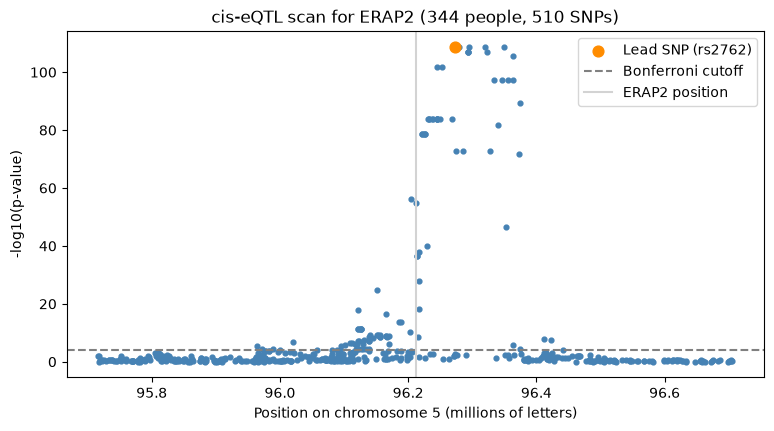

In [6]:
import matplotlib.pyplot as plt

number_of_tests = len(eqtl_results)
bonferroni_cutoff = 0.05 / number_of_tests
is_significant = eqtl_results["p_value"] < bonferroni_cutoff

print("Bonferroni cutoff:", bonferroni_cutoff)
print("Significant SNPs:", is_significant.sum(), "out of", number_of_tests)

lead_snp = eqtl_results.loc[eqtl_results["p_value"].idxmin()]

figure, axis = plt.subplots(figsize=(9, 4.5))
axis.scatter(eqtl_results["position"] / 1e6, eqtl_results["neg_log10_p"], s=12, color="steelblue")
axis.scatter(lead_snp["position"] / 1e6, lead_snp["neg_log10_p"], s=60, color="darkorange", label=f"Lead SNP ({lead_snp['snp_id']})")
axis.axhline(-np.log10(bonferroni_cutoff), color="gray", linestyle="--", label="Bonferroni cutoff")
axis.axvline(erap2_position / 1e6, color="lightgray", label="ERAP2 position")
axis.set_xlabel("Position on chromosome 5 (millions of letters)")
axis.set_ylabel("-log10(p-value)")
axis.set_title("cis-eQTL scan for ERAP2 (344 people, 510 SNPs)")
axis.legend()
plt.show()

**What I see:** The Bonferroni cutoff is 0.05 / 510 = 0.000098, and 101 of the 510 SNPs pass it. The tallest dots sit just to the right of ERAP2's listed position (the lead SNP is about 62,000 letters away), close to the gene. Instead of one tall dot there's a whole tower, because nearby SNPs are in LD with the strongest one and share its signal. The dots get shorter farther from the peak, since SNPs farther away are inherited together with it less often.

One limitation: the gray line is a single position from the expression file, not the full stretch of the gene. The task says to use `gene_annot.txt.gz` for the gene's start and end, which I don't have yet, so my window is centered on that one position.

### Step 7: Look at the lead SNP directly

A p-value is a summary. Here I look at the actual expression values for each genotype group at rs2762.

0 copies of T: 114 people, average expression 7.3
1 copies of T: 171 people, average expression 22.8
2 copies of T: 59 people, average expression 38.2


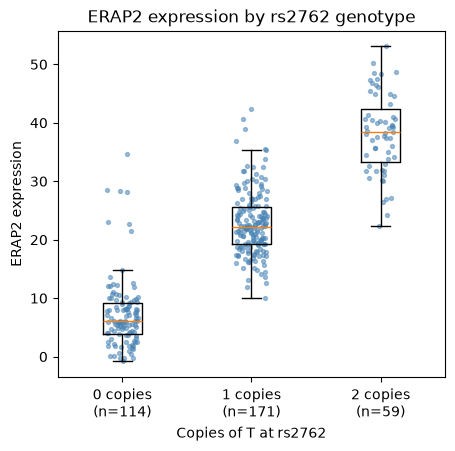

In [7]:
lead_snp_column = cis_snps.index[cis_snps["snp_id"] == lead_snp["snp_id"]][0]
lead_snp_copies = cis_genotypes[:, lead_snp_column]

groups = [erap2_expression[lead_snp_copies == copies] for copies in (0, 1, 2)]
labels = [f"{copies} copies\n(n={len(group)})" for copies, group in zip((0, 1, 2), groups)]

for copies, group in zip((0, 1, 2), groups):
    print(f"{copies} copies of {lead_snp['counted_allele']}: {len(group)} people, average expression {group.mean():.1f}")

figure, axis = plt.subplots(figsize=(5, 4.5))
axis.boxplot(groups, tick_labels=labels, showfliers=False)
for group_number, group in enumerate(groups, start=1):
    jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(group))
    axis.scatter(group_number + jitter, group, s=8, color="steelblue", alpha=0.5)
axis.set_xlabel(f"Copies of {lead_snp['counted_allele']} at {lead_snp['snp_id']}")
axis.set_ylabel("ERAP2 expression")
axis.set_title(f"ERAP2 expression by {lead_snp['snp_id']} genotype")
plt.show()

**What I see:** The three groups barely overlap. People with 0 copies of T (114 people) average about 7.3, people with 1 copy (171) average about 22.8, and people with 2 copies (59) average about 38.2. Each extra copy adds about 15, matching the slope from Step 5, and the steps are evenly spaced, so a straight line fits well.

### Step 8: How many SNPs are in a 1 Mb window around a gene? (Gradescope question 3)

ERAP2 had 510 SNPs, but that's one gene. Here I count SNPs in the ±500 kb window for every gene on chromosomes 1 to 22.

Genes counted: 22721
Average SNPs per 1 Mb window: 406.4
Median: 411.0
Middle 90% of genes: 162.0 to 630.0
Genes with 0 SNPs: 186


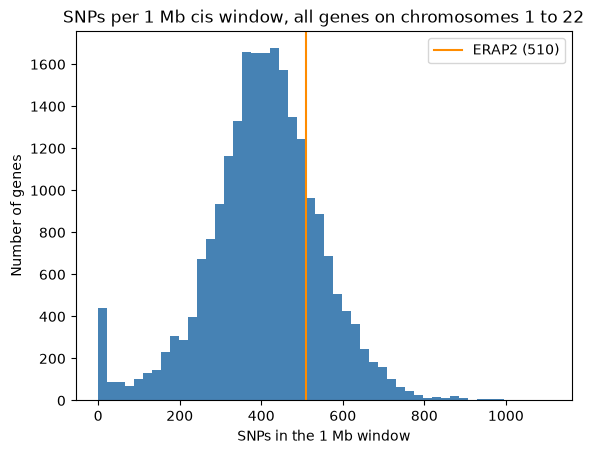

In [8]:
snps_per_window = []

for chromosome in range(1, 23):
    chromosome_snp_positions = np.sort(pd.read_csv(
        f"{genotype_folder}/1000G.EUR.{chromosome}.bim",
        sep=r"\s+", header=None, names=bim_column_names,
    )["position"].to_numpy())

    genes_on_chromosome = expression_table[expression_table["Chr"].astype(str) == str(chromosome)]
    gene_positions = genes_on_chromosome["Coord"].to_numpy()

    # Count SNPs between (gene position - 500 kb) and (gene position + 500 kb)
    first_snp = np.searchsorted(chromosome_snp_positions, gene_positions - cis_window_size, side="left")
    last_snp = np.searchsorted(chromosome_snp_positions, gene_positions + cis_window_size, side="right")
    snps_per_window.extend(last_snp - first_snp)

snps_per_window = pd.Series(snps_per_window)

print("Genes counted:", len(snps_per_window))
print("Average SNPs per 1 Mb window:", round(snps_per_window.mean(), 1))
print("Median:", snps_per_window.median())
print("Middle 90% of genes:", snps_per_window.quantile(0.05), "to", snps_per_window.quantile(0.95))
print("Genes with 0 SNPs:", (snps_per_window == 0).sum())

snps_per_window.plot(kind="hist", bins=50, color="steelblue")
plt.axvline(len(cis_snps), color="darkorange", label="ERAP2 (510)")
plt.xlabel("SNPs in the 1 Mb window")
plt.ylabel("Number of genes")
plt.title("SNPs per 1 Mb cis window, all genes on chromosomes 1 to 22")
plt.legend()
plt.show()

**What I see:** Across 22,721 genes, the average 1 Mb window has about 406 SNPs (median 411). Most genes (the middle 90%) have between 162 and 630, and 186 genes have none, likely genes in regions this SNP set barely covers. ERAP2's 510 is a bit above average.

This depends on the dataset. LDREF has only about 1.2 million mostly common SNPs. Full sequencing finds an SNV about every 1,000 letters on average per person (Lupski et al.), and GTEx found about 10 million common variants, so a 1 Mb window in full data would have thousands of variants.

## Readings guide

---

### 1. GTEx Consortium 2020, *Science*: eQTLs across human tissues

**What it's about:** The GTEx project measured gene expression in 49 tissues from 838 people who had died and donated tissue, and sequenced their whole genomes. Then it mapped eQTLs in every tissue, to understand how SNPs control genes and how that connects to disease.

**My notes:**
- Data: 15,201 RNA-seq samples from 838 donors (85% European American, 12% African American). Whole genomes were sequenced at about 32x depth.
- cis-eQTLs are everywhere. Almost every gene has one in at least one tissue: 94.7% of protein-coding genes. 43% of all common variants were an eQTL in at least one tissue.
- More people means more eQTLs found (correlation 0.95 between sample size and number of eGenes), mostly because bigger samples can detect smaller effects.
- Many genes have more than one independent eQTL (up to 50% of eGenes in the biggest tissues). This is called allelic heterogeneity.
- trans-eQTLs are rare: only 143 genes had one.
- Fine-mapping: finding the causal SNP is hard because of LD. The likely causal SNP usually narrows down to a median of about 6 candidates.
- Disease link: GWAS SNPs are more likely to be eQTLs than random SNPs (63% vs. 43%). 43% of GWAS loci shared a causal signal with an eQTL, suggesting many disease SNPs work by changing expression.
- Pleiotropy: a median of 57% of eQTL SNPs affect more than one gene in a tissue, and these SNPs are linked to more traits.
- Tissue sharing follows a U-shape: eQTLs are either shared by almost all tissues or specific to a few. Tissues with similar cell types share more eQTLs. Blood (and lab-grown LCLs, like my data) is an outlier, so it's not a perfect stand-in for other tissues.
- Their model: linear regression of normalized expression on genotype, adjusting for covariates like ancestry, sex, and hidden factors.

---

### 2. Nathan et al. 2022, *Nature*: eQTLs in single cells (methods)

**What it's about:** Instead of measuring a tissue as one mixed blob, this study measured more than 500,000 individual memory T cells (an immune cell) from 259 Peruvian people. They asked whether an eQTL's effect changes depending on the state a cell is in. My mentor, Tiffany Amariuta, is an author.

**My notes:**
- **Step 1, pseudobulk:** add up each gene's expression across all of a person's cells, then run a regular cis-eQTL test (SNPs within 1 Mb). This is like a GTEx-style analysis and found 6,511 eGenes, including **ERAP2**.
- **Step 2, single-cell model:** test each cell separately using a **Poisson mixed-effects model**. Poisson because single-cell data are counts (many zeros). Mixed-effects because many cells come from the same person and batch, so they aren't independent.
- They added an **interaction** between genotype and cell state, asking: does the SNP's effect get bigger or smaller as a cell becomes more of a certain type (like more cytotoxic)?
- About one third of the eQTLs changed with cell state. Autoimmune disease SNPs were enriched among these state-dependent eQTLs.
- A linear model on single cells gave false positives here, which is why they needed the Poisson model.
- They found 808 eQTLs that are likely population-specific, driven by SNPs common in Peruvians (MAF over 5%) but rare in Europeans.

**Compared to GTEx:**
| | GTEx | Nathan et al. |
|---|---|---|
| Unit | One tissue sample per person (mix of cells) | Each single cell |
| Model | Linear regression | Poisson mixed-effects regression |
| Cell type | Averaged together | Continuous cell states, with a genotype x state interaction |
| Can see effects specific to a cell state? | Mostly no (washed out in the mix) | Yes |

---

### 3. AJHG 2020 paper: how a scientific paper is structured

**What it's about:** I skim this to see how a genetics paper is laid out, since my Quarter 1 report follows the same structure.

**My notes:**
| Section | What it does |
|---|---|
| **Abstract** | The whole study in one paragraph: the problem, what was done, the main result, why it matters |
| **Introduction** | Background, what's missing in past work, and the question this paper answers |
| **Methods** | Data and steps in enough detail for someone else to repeat them |
| **Results** | What was found, with figures and numbers, without much interpretation |
| **Discussion** | What the results mean, limitations, and next steps |

## Week 3 answers

### Task questions

**1. Match sample IDs between the genotype and expression data.**
344 people are in both datasets. I kept them in the genotype file's order and pulled their expression values in that same order (Step 2).

**2. Run an eQTL analysis for one gene using SNPs within ±500 kb.**
For ERAP2 (chromosome 5), the cis window had 510 SNPs. 101 of them passed the Bonferroni cutoff (0.05 / 510 = 0.000098). The lead SNP, rs2762, has a slope of about 15.5 per copy of T, a p-value of 1.6e-109, and explains about 76% of the variation in ERAP2 expression. Five SNPs tied for the top spot because they have identical genotypes (LD).

**3. Software.**
Simple linear regression in Python (`scipy.stats.linregress`), looped over SNPs, with `bed-reader` to read the `.bed` file. PLINK's `--extract bed1` would do the window step.

**4. Bonus: LocusZoom plot.**
Done in Step 6. The plot shows a tall tower of significant SNPs just next to ERAP2.

### Gradescope questions

**1. What does pleiotropy mean?**
Pleiotropy is when one genetic variant affects more than one trait. For example, one SNP might change the expression of two different genes, or raise the risk of two different diseases. GTEx found it's common for eQTLs: a median of 57% of eQTL SNPs were linked to more than one gene in the same tissue, and those SNPs were also linked to more complex traits.

**2. Do eQTLs tend to be shared across cell types?**
Partly. GTEx found eQTLs tend to be either shared across almost all tissues or specific to just a few, and tissues made of similar cell types share more eQTLs. But even when an eQTL is shared, its strength can differ between cell types or cell states. Nathan et al. found about one third of eQTLs in memory T cells changed strength depending on the cell's state. So many eQTLs are shared, but cell type and state still matter.

**3. How many SNPs tend to be in a 1 Mb window around a gene?**
In my data, about 400. Across 22,721 genes, the average ±500 kb window held about 406 SNPs (median 411), and most genes had between about 160 and 630. ERAP2's window had 510. This dataset only includes about 1.2 million mostly common SNPs, so with full sequencing data a 1 Mb window would hold thousands of variants.